# RGB to Multispectral Image Translation
### UNet + ResBlock + CBAM Attention
---

In [ ]:
# Install dependencies
!pip install rasterio scikit-learn -q

In [ ]:
# Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os
import zipfile
import glob
import random
import time
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from pathlib import Path

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms.functional as TF

try:
    import rasterio
    HAS_RASTERIO = True
    print("rasterio available")
except ImportError:
    HAS_RASTERIO = False
    print("rasterio not found, using PIL fallback")

from PIL import Image
from sklearn.metrics import r2_score

print("All imports done.")

rasterio available
All imports done.


In [ ]:
class Config:
    ZIP_SEARCH_ROOTS = [
        "/content/drive/MyDrive/FYI",
        "/content/drive/MyDrive",
        "/content/drive",
        "/content",
        os.path.expanduser("~/FYI"),
        os.path.expanduser("~"),
        ".",
    ]
    ZIP_NAME        = "WeedyRice-RGBMS-DB"
    EXTRACTED_ROOT  = "/tmp/WeedyRice_extracted"

    IMG_H, IMG_W    = 256, 256
    MS_BANDS        = 4
    MS_EXTENSIONS   = [".tif", ".tiff", ".TIF", ".TIFF", ".png", ".jpg"]
    RGB_EXTENSIONS  = [".jpg", ".jpeg", ".JPG", ".png", ".PNG"]

    BATCH_SIZE      = 8
    NUM_EPOCHS      = 60
    LR              = 3e-4
    WEIGHT_DECAY    = 1e-4
    SCHEDULER_STEP  = 20
    SCHEDULER_GAMMA = 0.5
    VAL_SPLIT       = 0.15
    TEST_SPLIT      = 0.10
    SEED            = 42
    BASE_CHANNELS   = 64

    SAVE_DIR        = "./rgb2ms_outputs"
    MODEL_PATH      = "./rgb2ms_outputs/best_model.pth"
    DEVICE          = torch.device("cuda" if torch.cuda.is_available() else "cpu")

cfg = Config()
os.makedirs(cfg.SAVE_DIR, exist_ok=True)
random.seed(cfg.SEED)
np.random.seed(cfg.SEED)
torch.manual_seed(cfg.SEED)
print(f"Device: {cfg.DEVICE}")

Device: cuda


In [ ]:
def find_and_extract_zip():
    zip_path = None
    for root in cfg.ZIP_SEARCH_ROOTS:
        if not os.path.isdir(root):
            continue
        for f in glob.glob(os.path.join(root, "**", "*.zip"), recursive=True):
            if cfg.ZIP_NAME.lower() in os.path.basename(f).lower():
                zip_path = f
                break
        if zip_path:
            break

    if zip_path is None:
        for f in glob.glob("./**/*.zip", recursive=True):
            if cfg.ZIP_NAME.lower() in os.path.basename(f).lower():
                zip_path = f
                break

    if zip_path:
        print(f"Found zip: {zip_path}")
        if not os.path.exists(cfg.EXTRACTED_ROOT):
            print("Extracting ...")
            with zipfile.ZipFile(zip_path, 'r') as z:
                z.extractall(cfg.EXTRACTED_ROOT)
            print("Extraction complete.")
        else:
            print("Already extracted.")
        return cfg.EXTRACTED_ROOT
    else:
        print("Zip not found. Set cfg.EXTRACTED_ROOT manually.")
        return cfg.EXTRACTED_ROOT

def find_dataset_root(base):
    for root, dirs, _ in os.walk(base):
        if "RGB" in dirs and "Multispectral" in dirs:
            return root
    return base

extracted    = find_and_extract_zip()
dataset_root = find_dataset_root(extracted)
print(f"Dataset root: {dataset_root}")

Found zip: /content/drive/MyDrive/FYI/WeedyRice-RGBMS-DB (1).zip
Extracting ...
Extraction complete.
Dataset root: /tmp/WeedyRice_extracted/WeedyRice-RGBMS-DB


In [ ]:
def load_ms_image(path):
    ext = Path(path).suffix.lower()
    if ext in [".tif", ".tiff"] and HAS_RASTERIO:
        with rasterio.open(path) as src:
            arr = src.read().astype(np.float32)
        return arr
    else:
        img = np.array(Image.open(path).convert("RGB"), dtype=np.float32)
        return img.transpose(2, 0, 1)

def load_rgb_image(path):
    img = Image.open(path).convert("RGB")
    return np.array(img, dtype=np.float32).transpose(2, 0, 1)

def normalize(arr):
    out = arr.copy()
    for c in range(arr.shape[0]):
        mn, mx = arr[c].min(), arr[c].max()
        out[c] = (arr[c] - mn) / (mx - mn + 1e-8)
    return out

class WeedyRiceDataset(Dataset):
    def __init__(self, pairs, augment=False):
        self.pairs   = pairs
        self.augment = augment

    def __len__(self):
        return len(self.pairs)

    def _load_pair(self, rgb_path, ms_path):
        rgb = load_rgb_image(rgb_path)

        if os.path.isdir(ms_path):
            band_files = sorted([
                os.path.join(ms_path, f)
                for f in os.listdir(ms_path)
                if Path(f).suffix.lower() in [".tif", ".tiff", ".png", ".jpg"]
            ])[:cfg.MS_BANDS]
            bands = []
            for bf in band_files:
                b = load_ms_image(bf)
                bands.append(b[0] if b.ndim == 3 else b)
            ms = np.stack(bands, axis=0).astype(np.float32)
        else:
            ms = load_ms_image(ms_path)
            if ms.shape[0] > cfg.MS_BANDS:
                ms = ms[:cfg.MS_BANDS]
            elif ms.shape[0] < cfg.MS_BANDS:
                pad = np.repeat(ms[-1:], cfg.MS_BANDS - ms.shape[0], axis=0)
                ms = np.concatenate([ms, pad], axis=0)

        rgb = normalize(rgb)
        ms  = normalize(ms)

        rgb_t = torch.from_numpy(rgb)
        ms_t  = torch.from_numpy(ms)
        rgb_t = F.interpolate(rgb_t.unsqueeze(0), (cfg.IMG_H, cfg.IMG_W),
                              mode="bilinear", align_corners=False).squeeze(0)
        ms_t  = F.interpolate(ms_t.unsqueeze(0), (cfg.IMG_H, cfg.IMG_W),
                              mode="bilinear", align_corners=False).squeeze(0)

        if self.augment:
            if random.random() > 0.5:
                rgb_t = TF.hflip(rgb_t)
                ms_t  = TF.hflip(ms_t)
            if random.random() > 0.5:
                rgb_t = TF.vflip(rgb_t)
                ms_t  = TF.vflip(ms_t)
            angle = random.choice([0, 90, 180, 270])
            if angle:
                rgb_t = TF.rotate(rgb_t, angle)
                ms_t  = TF.rotate(ms_t,  angle)

        return rgb_t, ms_t

    def __getitem__(self, idx):
        rgb_path, ms_path = self.pairs[idx]
        return self._load_pair(rgb_path, ms_path)

def build_pairs(dataset_root):
    rgb_dir = os.path.join(dataset_root, "RGB")
    ms_dir  = os.path.join(dataset_root, "Multispectral")

    rgb_files = sorted([
        f for f in os.listdir(rgb_dir)
        if Path(f).suffix.lower() in [e.lower() for e in cfg.RGB_EXTENSIONS]
    ])

    pairs = []
    for rf in rgb_files:
        stem  = Path(rf).stem
        rgb_p = os.path.join(rgb_dir, rf)
        ms_found = None

        for ext in cfg.MS_EXTENSIONS:
            candidate = os.path.join(ms_dir, stem + ext)
            if os.path.exists(candidate):
                ms_found = candidate
                break

        if ms_found is None:
            candidate_dir = os.path.join(ms_dir, stem)
            if os.path.isdir(candidate_dir):
                ms_found = candidate_dir

        if ms_found is None:
            for f in os.listdir(ms_dir):
                if f.startswith(stem) and Path(f).suffix.lower() in cfg.MS_EXTENSIONS:
                    ms_found = os.path.join(ms_dir, f)
                    break

        if ms_found:
            pairs.append((rgb_p, ms_found))

    print(f"Matched {len(pairs)} RGB-MS pairs out of {len(rgb_files)} RGB files.")
    if len(pairs) == 0:
        raise RuntimeError("No pairs found! Check dataset folder structure.")
    return pairs

def split_pairs(pairs):
    random.shuffle(pairs)
    n      = len(pairs)
    n_test = max(1, int(n * cfg.TEST_SPLIT))
    n_val  = max(1, int(n * cfg.VAL_SPLIT))
    test   = pairs[:n_test]
    val    = pairs[n_test:n_test + n_val]
    train  = pairs[n_test + n_val:]
    print(f"Split => Train={len(train)}, Val={len(val)}, Test={len(test)}")
    return train, val, test

pairs = build_pairs(dataset_root)
train_pairs, val_pairs, test_pairs = split_pairs(pairs)

train_ds = WeedyRiceDataset(train_pairs, augment=True)
val_ds   = WeedyRiceDataset(val_pairs,   augment=False)
test_ds  = WeedyRiceDataset(test_pairs,  augment=False)

train_loader = DataLoader(train_ds, batch_size=cfg.BATCH_SIZE, shuffle=True,
                          num_workers=2, pin_memory=True, drop_last=True)
val_loader   = DataLoader(val_ds,   batch_size=cfg.BATCH_SIZE, shuffle=False, num_workers=2)
test_loader  = DataLoader(test_ds,  batch_size=cfg.BATCH_SIZE, shuffle=False, num_workers=2)

print("Dataloaders ready.")

Matched 734 RGB-MS pairs out of 734 RGB files.
Split => Train=551, Val=110, Test=73
Dataloaders ready.


In [ ]:
class ChannelAttention(nn.Module):
    def __init__(self, ch, r=16):
        super().__init__()
        self.avg = nn.AdaptiveAvgPool2d(1)
        self.max = nn.AdaptiveMaxPool2d(1)
        self.fc  = nn.Sequential(
            nn.Linear(ch, ch // r, bias=False),
            nn.ReLU(),
            nn.Linear(ch // r, ch, bias=False)
        )
        self.sig = nn.Sigmoid()

    def forward(self, x):
        b, c, _, _ = x.shape
        a = self.fc(self.avg(x).view(b, c))
        m = self.fc(self.max(x).view(b, c))
        return x * self.sig((a + m).view(b, c, 1, 1))

class SpatialAttention(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv = nn.Conv2d(2, 1, 7, padding=3, bias=False)
        self.sig  = nn.Sigmoid()

    def forward(self, x):
        avg = x.mean(dim=1, keepdim=True)
        mx  = x.max(dim=1, keepdim=True).values
        return x * self.sig(self.conv(torch.cat([avg, mx], dim=1)))

class CBAM(nn.Module):
    def __init__(self, ch):
        super().__init__()
        self.ca = ChannelAttention(ch)
        self.sa = SpatialAttention()

    def forward(self, x):
        return self.sa(self.ca(x))

class ResBlock(nn.Module):
    def __init__(self, ch):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(ch, ch, 3, padding=1, bias=False),
            nn.BatchNorm2d(ch),
            nn.LeakyReLU(0.1, inplace=True),
            nn.Conv2d(ch, ch, 3, padding=1, bias=False),
            nn.BatchNorm2d(ch),
        )
        self.cbam = CBAM(ch)
        self.act  = nn.LeakyReLU(0.1, inplace=True)

    def forward(self, x):
        return self.act(self.cbam(self.block(x)) + x)

class EncoderBlock(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.LeakyReLU(0.1, inplace=True),
            ResBlock(out_ch),
        )
        self.pool = nn.MaxPool2d(2)

    def forward(self, x):
        skip = self.conv(x)
        return self.pool(skip), skip

class DecoderBlock(nn.Module):
    def __init__(self, in_ch, skip_ch, out_ch):
        super().__init__()
        self.up   = nn.ConvTranspose2d(in_ch, out_ch, 2, stride=2)
        self.conv = nn.Sequential(
            nn.Conv2d(out_ch + skip_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.LeakyReLU(0.1, inplace=True),
            ResBlock(out_ch),
        )

    def forward(self, x, skip):
        x = self.up(x)
        if x.shape != skip.shape:
            x = F.interpolate(x, size=skip.shape[2:], mode="bilinear", align_corners=False)
        return self.conv(torch.cat([x, skip], dim=1))

class RGB2MS_UNet(nn.Module):
    def __init__(self, in_ch=3, out_ch=4, base=64):
        super().__init__()
        b = base
        self.enc1 = EncoderBlock(in_ch, b)
        self.enc2 = EncoderBlock(b,     b * 2)
        self.enc3 = EncoderBlock(b * 2, b * 4)
        self.enc4 = EncoderBlock(b * 4, b * 8)
        self.bottleneck = nn.Sequential(
            nn.Conv2d(b * 8, b * 16, 3, padding=1, bias=False),
            nn.BatchNorm2d(b * 16),
            nn.LeakyReLU(0.1, inplace=True),
            ResBlock(b * 16),
            ResBlock(b * 16),
        )
        self.dec4 = DecoderBlock(b * 16, b * 8, b * 8)
        self.dec3 = DecoderBlock(b * 8,  b * 4, b * 4)
        self.dec2 = DecoderBlock(b * 4,  b * 2, b * 2)
        self.dec1 = DecoderBlock(b * 2,  b,     b)
        self.head = nn.Sequential(
            nn.Conv2d(b, b // 2, 3, padding=1),
            nn.LeakyReLU(0.1, inplace=True),
            nn.Conv2d(b // 2, out_ch, 1),
            nn.Sigmoid()
        )

    def forward(self, x):
        x1, s1 = self.enc1(x)
        x2, s2 = self.enc2(x1)
        x3, s3 = self.enc3(x2)
        x4, s4 = self.enc4(x3)
        b      = self.bottleneck(x4)
        d4     = self.dec4(b,  s4)
        d3     = self.dec3(d4, s3)
        d2     = self.dec2(d3, s2)
        d1     = self.dec1(d2, s1)
        return self.head(d1)

model = RGB2MS_UNet(in_ch=3, out_ch=cfg.MS_BANDS, base=cfg.BASE_CHANNELS).to(cfg.DEVICE)
total_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Model parameters: {total_params / 1e6:.2f}M")

Model parameters: 65.99M


In [ ]:
class CombinedLoss(nn.Module):
    def __init__(self, w_l1=0.5, w_mse=0.3, w_grad=0.2):
        super().__init__()
        self.w_l1   = w_l1
        self.w_mse  = w_mse
        self.w_grad = w_grad

    def gradient_loss(self, pred, target):
        def grad(t):
            dx = t[:, :, :, 1:] - t[:, :, :, :-1]
            dy = t[:, :, 1:, :] - t[:, :, :-1, :]
            return dx, dy
        pdx, pdy = grad(pred)
        tdx, tdy = grad(target)
        return F.l1_loss(pdx, tdx) + F.l1_loss(pdy, tdy)

    def forward(self, pred, target):
        l1  = F.l1_loss(pred, target)
        mse = F.mse_loss(pred, target)
        grd = self.gradient_loss(pred, target)
        return self.w_l1 * l1 + self.w_mse * mse + self.w_grad * grd

def compute_r2(pred, target):
    p = pred.detach().cpu().numpy().flatten()
    t = target.detach().cpu().numpy().flatten()
    return r2_score(t, p)

def compute_psnr(pred, target):
    mse = F.mse_loss(pred, target).item()
    return 10 * np.log10(1.0 / (mse + 1e-8))

criterion = CombinedLoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=cfg.LR, weight_decay=cfg.WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.StepLR(optimizer,
                                             step_size=cfg.SCHEDULER_STEP,
                                             gamma=cfg.SCHEDULER_GAMMA)
print("Loss, optimizer, scheduler ready.")

Loss, optimizer, scheduler ready.


In [ ]:
def train_one_epoch(model, loader, optimizer, criterion, device):
    model.train()
    total_loss = 0.0
    for rgb, ms in loader:
        rgb, ms = rgb.to(device), ms.to(device)
        optimizer.zero_grad()
        pred = model(rgb)
        loss = criterion(pred, ms)
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()
        total_loss += loss.item()
    return total_loss / len(loader)

@torch.no_grad()
def evaluate(model, loader, criterion, device):
    model.eval()
    total_loss = total_r2 = total_psnr = 0.0
    for rgb, ms in loader:
        rgb, ms = rgb.to(device), ms.to(device)
        pred = model(rgb)
        total_loss += criterion(pred, ms).item()
        total_r2   += compute_r2(pred, ms)
        total_psnr += compute_psnr(pred, ms)
    n = len(loader)
    return total_loss / n, total_r2 / n, total_psnr / n

history    = {"train_loss": [], "val_loss": [], "val_r2": [], "val_psnr": []}
best_r2    = -np.inf
best_epoch = 0

print(f"Starting {cfg.NUM_EPOCHS} epochs on {cfg.DEVICE}")
print("-" * 75)

for epoch in range(1, cfg.NUM_EPOCHS + 1):
    t0 = time.time()
    tr_loss                    = train_one_epoch(model, train_loader, optimizer, criterion, cfg.DEVICE)
    val_loss, val_r2, val_psnr = evaluate(model, val_loader, criterion, cfg.DEVICE)
    scheduler.step()

    history["train_loss"].append(tr_loss)
    history["val_loss"].append(val_loss)
    history["val_r2"].append(val_r2)
    history["val_psnr"].append(val_psnr)

    flag = ""
    if val_r2 > best_r2:
        best_r2    = val_r2
        best_epoch = epoch
        torch.save(model.state_dict(), cfg.MODEL_PATH)
        flag = " [BEST]"

    elapsed = time.time() - t0
    print(f"Epoch [{epoch:3d}/{cfg.NUM_EPOCHS}] "
          f"TrainLoss={tr_loss:.4f}  ValLoss={val_loss:.4f}  "
          f"R2={val_r2:.4f}  PSNR={val_psnr:.2f}dB  "
          f"({elapsed:.1f}s){flag}")

print(f"\nBest R2={best_r2:.4f} at epoch {best_epoch}")

Starting 60 epochs on cuda
---------------------------------------------------------------------------
Epoch [  1/60] TrainLoss=0.0920  ValLoss=0.0825  R2=0.0209  PSNR=16.95dB  (71.9s) [BEST]
Epoch [  2/60] TrainLoss=0.0821  ValLoss=0.0776  R2=0.1046  PSNR=17.33dB  (71.1s) [BEST]
Epoch [  3/60] TrainLoss=0.0811  ValLoss=0.0734  R2=0.1751  PSNR=17.63dB  (71.3s) [BEST]
Epoch [  4/60] TrainLoss=0.0805  ValLoss=0.0762  R2=0.1089  PSNR=17.38dB  (69.8s)
Epoch [  5/60] TrainLoss=0.0800  ValLoss=0.0782  R2=0.0563  PSNR=17.19dB  (70.0s)
Epoch [  6/60] TrainLoss=0.0792  ValLoss=0.0744  R2=0.1331  PSNR=17.51dB  (70.5s)
Epoch [  7/60] TrainLoss=0.0791  ValLoss=0.0791  R2=0.0114  PSNR=17.03dB  (69.5s)
Epoch [  8/60] TrainLoss=0.0791  ValLoss=0.0770  R2=0.0818  PSNR=17.29dB  (69.5s)
Epoch [  9/60] TrainLoss=0.0795  ValLoss=0.0729  R2=0.1639  PSNR=17.60dB  (71.3s)
Epoch [ 10/60] TrainLoss=0.0788  ValLoss=0.0735  R2=0.1605  PSNR=17.63dB  (69.9s)
Epoch [ 11/60] TrainLoss=0.0791  ValLoss=0.0733  R2=0.15

In [ ]:
print("Loading best model for test evaluation...")
model.load_state_dict(torch.load(cfg.MODEL_PATH, map_location=cfg.DEVICE))
test_loss, test_r2, test_psnr = evaluate(model, test_loader, criterion, cfg.DEVICE)

print("=" * 50)
print("  TEST RESULTS")
print(f"  Loss : {test_loss:.4f}")
print(f"  R2   : {test_r2:.4f}")
print(f"  PSNR : {test_psnr:.2f} dB")
print("=" * 50)

Loading best model for test evaluation...
  TEST RESULTS
  Loss : 0.0770
  R2   : -0.0521
  PSNR : 17.58 dB


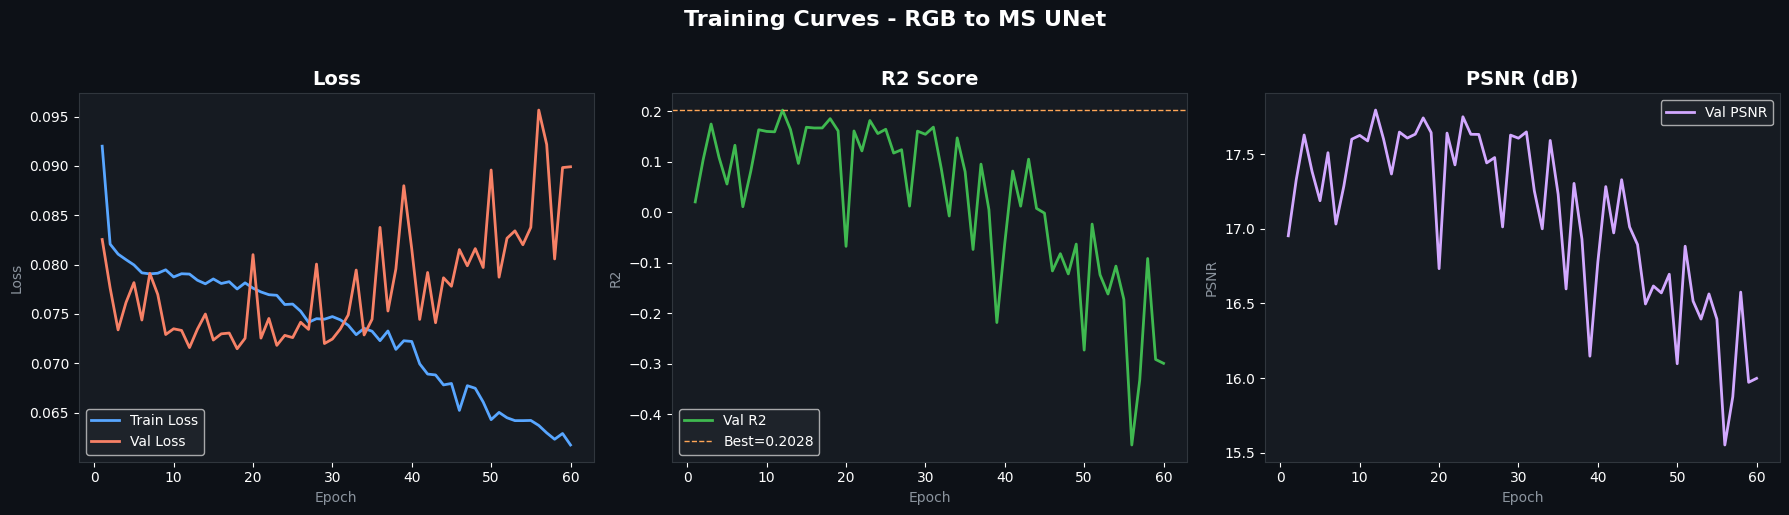

Training curves saved.


In [ ]:
BAND_NAMES  = ["Green", "Red", "RedEdge", "NIR"]
BAND_CMAPS  = ["Greens", "Reds", "RdPu", "YlOrBr"]
BAND_COLORS = ["#3fb950", "#f78166", "#d2a8ff", "#ffa657"]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.patch.set_facecolor("#0d1117")
for ax in axes:
    ax.set_facecolor("#161b22")
    ax.tick_params(colors="white")
    for spine in ax.spines.values():
        spine.set_color("#30363d")
    for label in ax.get_xticklabels() + ax.get_yticklabels():
        label.set_color("white")

epochs = range(1, len(history["train_loss"]) + 1)

axes[0].plot(epochs, history["train_loss"], color="#58a6ff", lw=2, label="Train Loss")
axes[0].plot(epochs, history["val_loss"],   color="#f78166", lw=2, label="Val Loss")
axes[0].set_title("Loss",   color="white", fontsize=14, fontweight="bold")
axes[0].set_xlabel("Epoch", color="#8b949e")
axes[0].set_ylabel("Loss",  color="#8b949e")
axes[0].legend(facecolor="#21262d", labelcolor="white")

best_r2_val = max(history["val_r2"])
axes[1].plot(epochs, history["val_r2"], color="#3fb950", lw=2, label="Val R2")
axes[1].axhline(y=best_r2_val, color="#ffa657", lw=1, ls="--", label=f"Best={best_r2_val:.4f}")
axes[1].set_title("R2 Score", color="white", fontsize=14, fontweight="bold")
axes[1].set_xlabel("Epoch",   color="#8b949e")
axes[1].set_ylabel("R2",      color="#8b949e")
axes[1].legend(facecolor="#21262d", labelcolor="white")

axes[2].plot(epochs, history["val_psnr"], color="#d2a8ff", lw=2, label="Val PSNR")
axes[2].set_title("PSNR (dB)", color="white", fontsize=14, fontweight="bold")
axes[2].set_xlabel("Epoch",    color="#8b949e")
axes[2].set_ylabel("PSNR",     color="#8b949e")
axes[2].legend(facecolor="#21262d", labelcolor="white")

plt.suptitle("Training Curves - RGB to MS UNet",
             color="white", fontsize=16, fontweight="bold", y=1.02)
plt.tight_layout()
plt.savefig(os.path.join(cfg.SAVE_DIR, "training_curves.png"), dpi=150,
            bbox_inches="tight", facecolor=fig.get_facecolor())
plt.show()
print("Training curves saved.")

In [ ]:
model.eval()
n_samples = 4
indices = random.sample(range(len(test_ds)), min(n_samples, len(test_ds)))

fig = plt.figure(figsize=(20, 5 * len(indices)))
fig.patch.set_facecolor("#0d1117")
gs = gridspec.GridSpec(len(indices), 9, figure=fig, hspace=0.35, wspace=0.05)

col_titles = (["Input RGB"] +
              [f"GT {b}"   for b in BAND_NAMES] +
              [f"Pred {b}" for b in BAND_NAMES])

with torch.no_grad():
    for row, idx in enumerate(indices):
        rgb, ms_gt = test_ds[idx]
        pred_ms    = model(rgb.unsqueeze(0).to(cfg.DEVICE)).squeeze(0).cpu()

        rgb_np  = rgb.permute(1, 2, 0).numpy()
        gt_np   = ms_gt.numpy()
        pred_np = pred_ms.numpy()

        ax = fig.add_subplot(gs[row, 0])
        ax.imshow(np.clip(rgb_np, 0, 1))
        if row == 0:
            ax.set_title(col_titles[0], color="white", fontsize=9, fontweight="bold")
        ax.set_ylabel(f"Sample {idx + 1}", color="#8b949e", fontsize=9)
        ax.axis("off")

        for b in range(4):
            ax = fig.add_subplot(gs[row, 1 + b])
            ax.imshow(gt_np[b], cmap=BAND_CMAPS[b], vmin=0, vmax=1)
            if row == 0:
                ax.set_title(col_titles[1 + b], color="white", fontsize=9, fontweight="bold")
            ax.axis("off")

        for b in range(4):
            ax = fig.add_subplot(gs[row, 5 + b])
            ax.imshow(pred_np[b], cmap=BAND_CMAPS[b], vmin=0, vmax=1)
            if row == 0:
                ax.set_title(col_titles[5 + b], color="white", fontsize=9, fontweight="bold")
            ax.axis("off")
            r2_val = r2_score(gt_np[b].flatten(), pred_np[b].flatten())
            ax.set_xlabel(f"R2={r2_val:.3f}", color="#3fb950", fontsize=8)

fig.suptitle("RGB to Multispectral Prediction | GT vs Predicted",
             color="white", fontsize=15, fontweight="bold", y=1.01)
plt.savefig(os.path.join(cfg.SAVE_DIR, "predictions.png"), dpi=150,
            bbox_inches="tight", facecolor=fig.get_facecolor())
plt.show()
print("Prediction grid saved.")

Output hidden; open in https://colab.research.google.com to view.

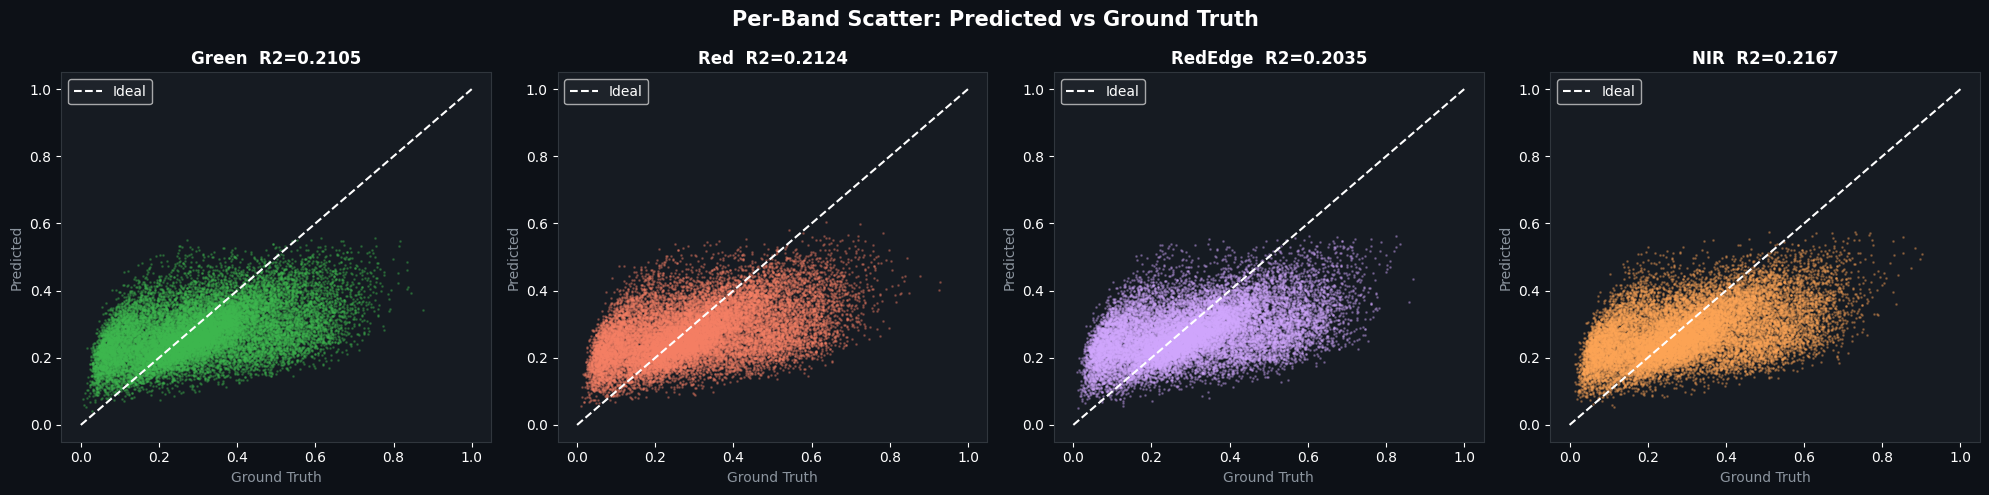

Scatter plot saved.


In [ ]:
model.eval()
all_gt   = [[] for _ in range(4)]
all_pred = [[] for _ in range(4)]

with torch.no_grad():
    for rgb, ms in test_loader:
        pred = model(rgb.to(cfg.DEVICE)).cpu()
        for b in range(4):
            all_gt[b].append(ms[:, b].numpy().flatten())
            all_pred[b].append(pred[:, b].numpy().flatten())

fig, axes = plt.subplots(1, 4, figsize=(20, 5))
fig.patch.set_facecolor("#0d1117")

for b, ax in enumerate(axes):
    gt   = np.concatenate(all_gt[b])
    pred = np.concatenate(all_pred[b])
    if len(gt) > 20000:
        idx = np.random.choice(len(gt), 20000, replace=False)
        gt, pred = gt[idx], pred[idx]

    r2_val = r2_score(gt, pred)
    ax.set_facecolor("#161b22")
    ax.scatter(gt, pred, alpha=0.3, s=1, color=BAND_COLORS[b])
    ax.plot([0, 1], [0, 1], "w--", lw=1.5, label="Ideal")
    ax.set_title(f"{BAND_NAMES[b]}  R2={r2_val:.4f}",
                 color="white", fontsize=12, fontweight="bold")
    ax.set_xlabel("Ground Truth", color="#8b949e")
    ax.set_ylabel("Predicted",    color="#8b949e")
    ax.tick_params(colors="white")
    for spine in ax.spines.values():
        spine.set_color("#30363d")
    for label in ax.get_xticklabels() + ax.get_yticklabels():
        label.set_color("white")
    ax.legend(facecolor="#21262d", labelcolor="white")

fig.suptitle("Per-Band Scatter: Predicted vs Ground Truth",
             color="white", fontsize=15, fontweight="bold")
plt.tight_layout()
plt.savefig(os.path.join(cfg.SAVE_DIR, "band_scatter.png"), dpi=150,
            bbox_inches="tight", facecolor=fig.get_facecolor())
plt.show()
print("Scatter plot saved.")

In [ ]:
import shutil

drive_out = "/content/drive/MyDrive/rgb2ms_outputs"
shutil.copytree(cfg.SAVE_DIR, drive_out, dirs_exist_ok=True)
print(f"All outputs copied to Google Drive: {drive_out}")

All outputs copied to Google Drive: /content/drive/MyDrive/rgb2ms_outputs
